# Sea surface temperature projections

Multi-model CMIP6 projections prepared by CSIRO on a common 1° Pacific grid. Every model's annual series is averaged over each EEZ and over all the EEZs together (cosine-of-latitude weights) and expressed as the change relative to its own 2015–2035 mean. For each indicator:

* **Trend map** — linear trend over 2015–2100 of the multi-model median change in each EEZ, one panel per scenario.
* **Warming-level map** — multi-model median change in each EEZ in the year each scenario first reaches each global warming level, one figure per scenario on a shared colour scale.
* **All-EEZ box plots** — spread across models at each warming level for the mean over all the Pacific EEZs.

```{glue:figure} tos_fig
:scale: 60%
:align: center
```

**Figure. Change in sea surface temperature relative to 2015–2035 in each Pacific EEZ at the global warming levels** (multi-model median, `map_scenario`).

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Regional helpers come from `functions/projections_regional.py` (EEZ and all-EEZ means, maps, box plots) and `functions/projections.py` (data access, warming levels); the box plots use `ind_setup.plotting_projections` from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
sys.path.append("../../../../functions")
import projections as prj
import projections_regional as reg

### Configuration

Scenarios and global warming levels are the ones of the national projections ([`../../National/00_warming_levels.ipynb`](../../National/00_warming_levels.ipynb)). Maps of the change at warming levels are drawn for every scenario on a shared colour scale (`map_scenario` is the one shown at the top of the notebook); box plots show every scenario. Figures go to `outputs/figures/regional_pacific/PRJ_*` and tables to `outputs/tables/regional_pacific/PRJ_*`.

In [3]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
map_scenario = "ssp370"
scenario_info = prj.load_warming_levels(ssp_scenarios)

eez = reg.load_eez()
fig_dir = Path("../../../../outputs/figures/regional_pacific")
tables_dir = Path("../../../../outputs/tables/regional_pacific")
fig_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

## Sea surface temperature

Annual mean sea surface temperature (°C) from monthly SST.

**Sea surface temperature: linear trend 2015–2100 of the multi-model median (°C per decade), by EEZ**

,SSP126,SSP245,SSP370,SSP585
American Samoa,0.0546,0.1577,0.2660,0.3367
Cook Islands,0.0562,0.1600,0.2653,0.3318
Fiji,0.0498,0.1612,0.2718,0.3516
French Polynesia,0.0513,0.1515,0.2496,0.3169
Hawaii,0.0663,0.1845,0.3028,0.4104
Howland Island and Baker Island,0.0835,0.2150,0.3525,0.4467
Jarvis Island,0.0901,0.2204,0.3577,0.4633
Johnston Atoll,0.0657,0.1858,0.3097,0.4067
Kiribati,0.0773,0.2061,0.3210,0.4023
Line Group,0.0757,0.1931,0.3136,0.3929


**Change in sea surface temperature vs 2015–2035 at the global warming levels (SSP126, multi-model median, °C), by EEZ**

,+1.5°C (2032)
region,
American Samoa,0.108
Cook Islands,0.097
Fiji,0.195
French Polynesia,0.060
Hawaii,0.196
Howland Island and Baker Island,0.242
Jarvis Island,0.107
Johnston Atoll,0.201
Kiribati,0.277


**Change in sea surface temperature vs 2015–2035 at the global warming levels (SSP245, multi-model median, °C), by EEZ**

,+1.5°C (2030),+2.0°C (2052),+2.5°C (2079)
region,,,
American Samoa,0.045,0.534,0.870
Cook Islands,0.041,0.526,0.903
Fiji,0.103,0.584,0.987
French Polynesia,0.015,0.503,0.842
Hawaii,0.095,0.644,1.085
Howland Island and Baker Island,-0.011,0.765,1.368
Jarvis Island,-0.037,0.819,1.332
Johnston Atoll,0.142,0.609,1.053
Kiribati,-0.037,0.745,1.378


... (2 outputs left out)

**Change in sea surface temperature vs 2015–2035 at the global warming levels (SSP585, multi-model median, °C), by EEZ**

,+1.5°C (2027),+2.0°C (2041),+2.5°C (2053),+3.0°C (2064)
region,,,,
American Samoa,0.104,0.455,0.802,1.285
Cook Islands,0.030,0.422,0.734,1.188
Fiji,0.012,0.529,0.766,1.224
French Polynesia,-0.006,0.374,0.660,1.178
Hawaii,0.132,0.535,0.949,1.374
Howland Island and Baker Island,0.269,0.331,1.085,1.560
Jarvis Island,0.118,0.294,1.070,1.452
Johnston Atoll,0.085,0.499,0.820,1.352
Kiribati,0.192,0.440,1.104,1.589


**Change in sea surface temperature vs 2015–2035 at the global warming levels (°C): spread across models in All Pacific EEZs**

,Region,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,All Pacific EEZs,SSP126,+1.5°C,2032,35,0.155,-0.072,0.281,-0.238,0.323
1,All Pacific EEZs,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,All Pacific EEZs,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,All Pacific EEZs,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,All Pacific EEZs,SSP245,+1.5°C,2030,35,0.107,-0.124,0.226,-0.351,0.352
5,All Pacific EEZs,SSP245,+2.0°C,2052,35,0.559,0.373,0.820,0.263,1.047
6,All Pacific EEZs,SSP245,+2.5°C,2079,35,1.063,0.602,1.368,0.446,1.537
7,All Pacific EEZs,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,All Pacific EEZs,SSP370,+1.5°C,2030,33,0.100,-0.104,0.224,-0.284,0.325
9,All Pacific EEZs,SSP370,+2.0°C,2046,33,0.506,0.354,0.805,0.176,0.979


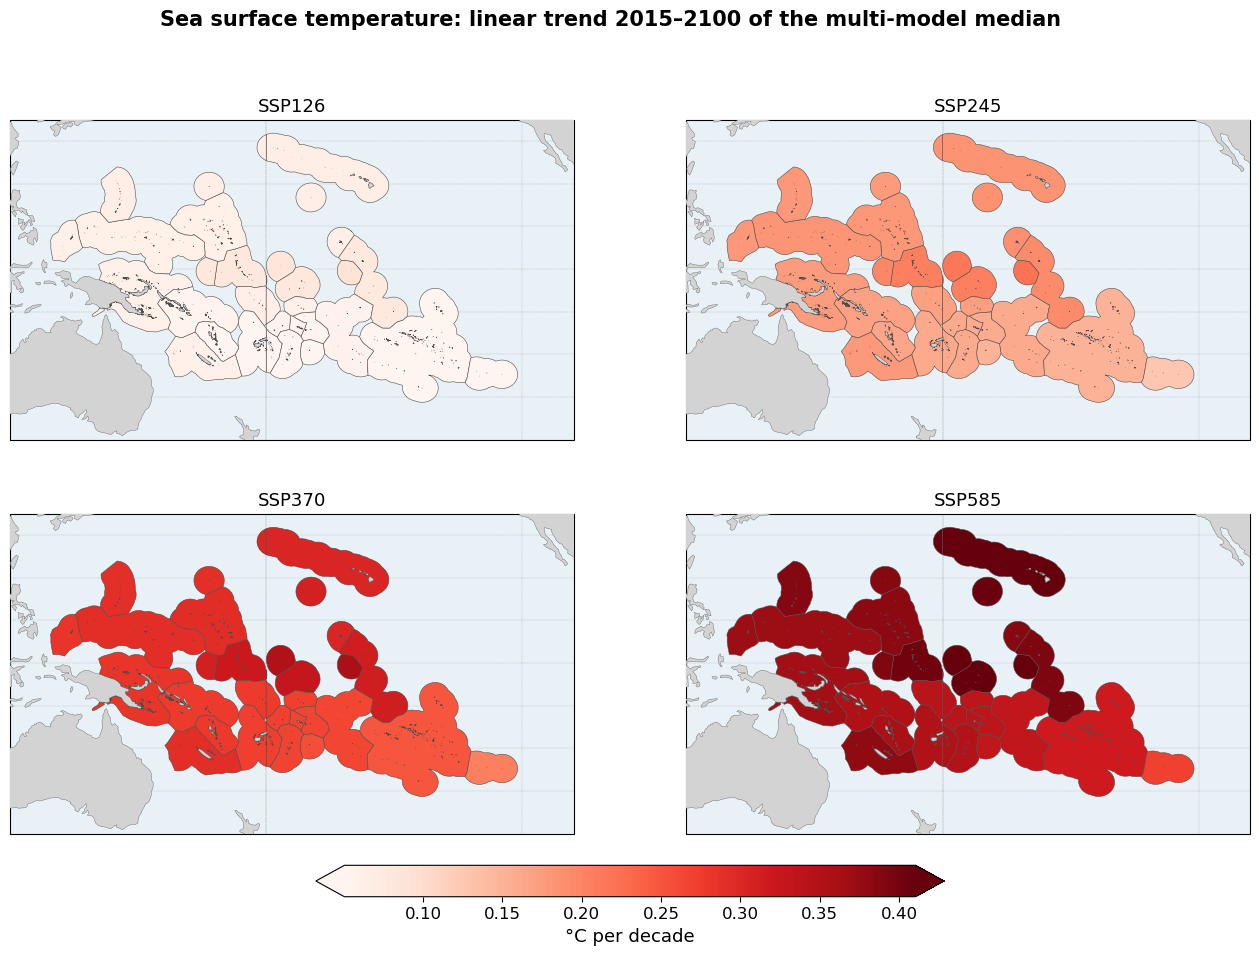

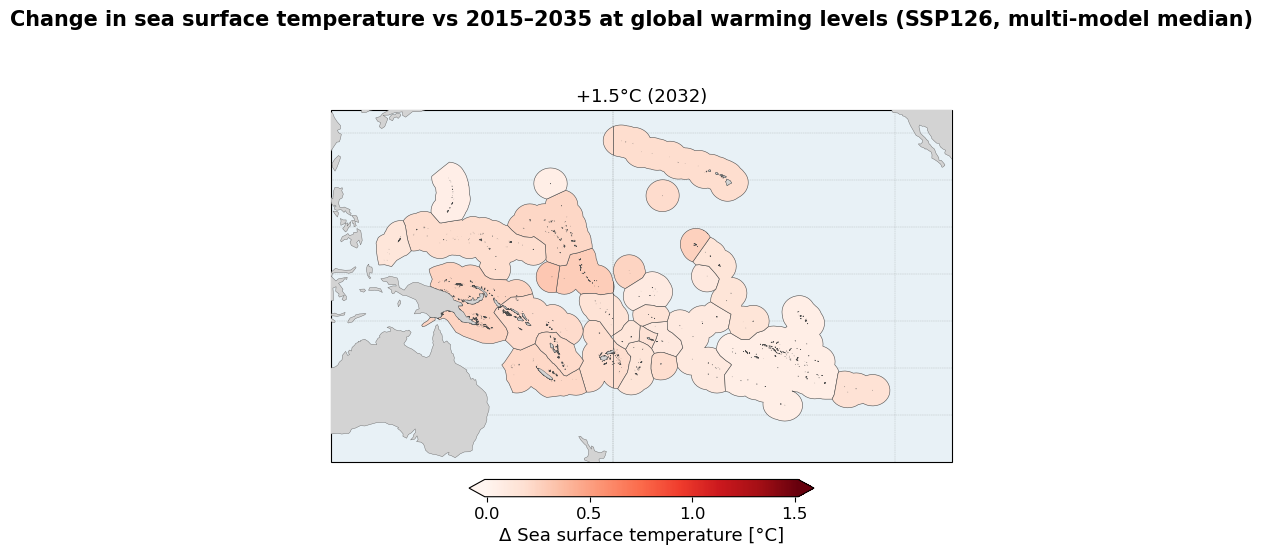

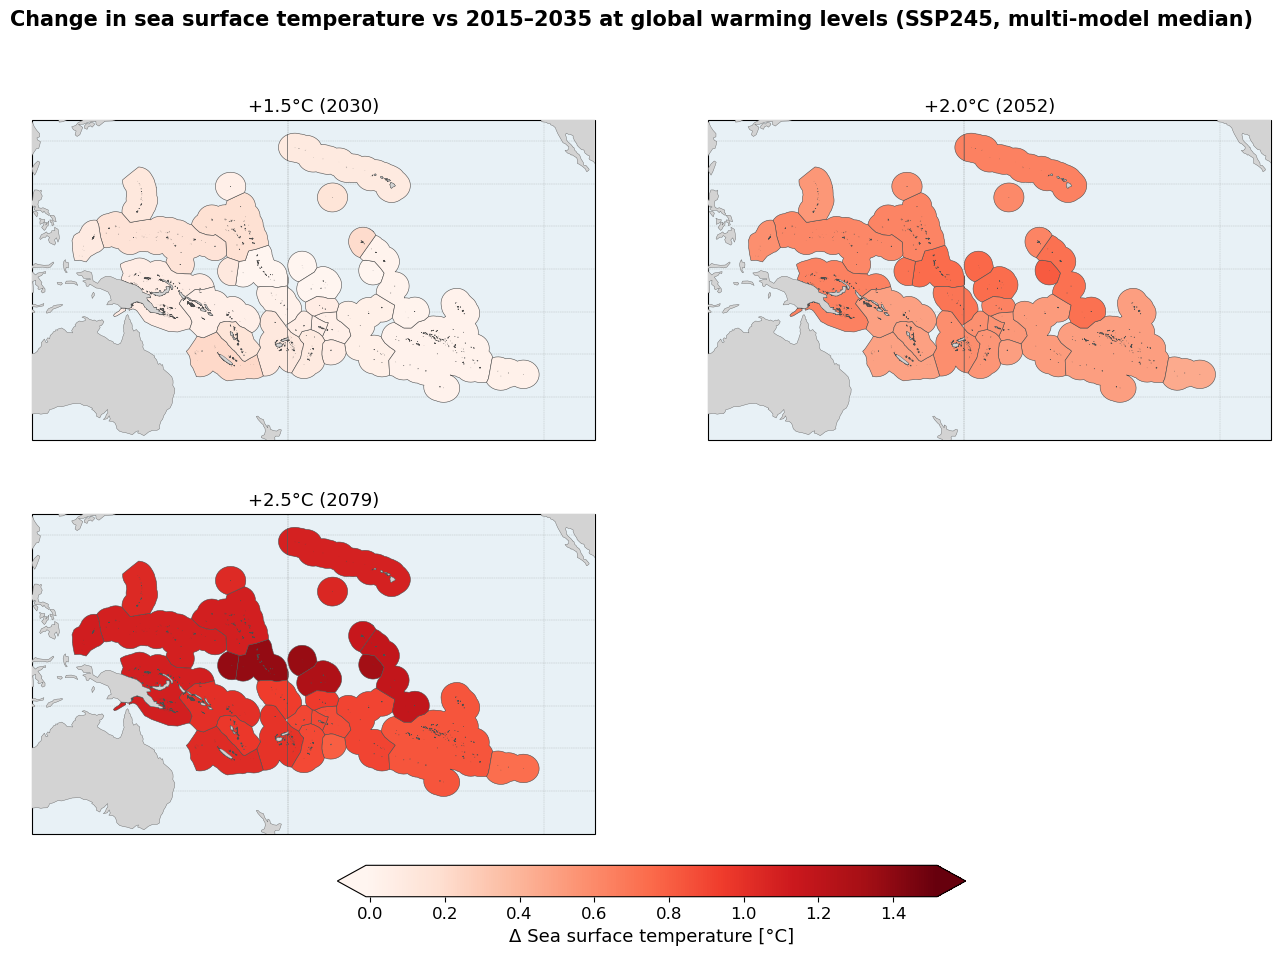

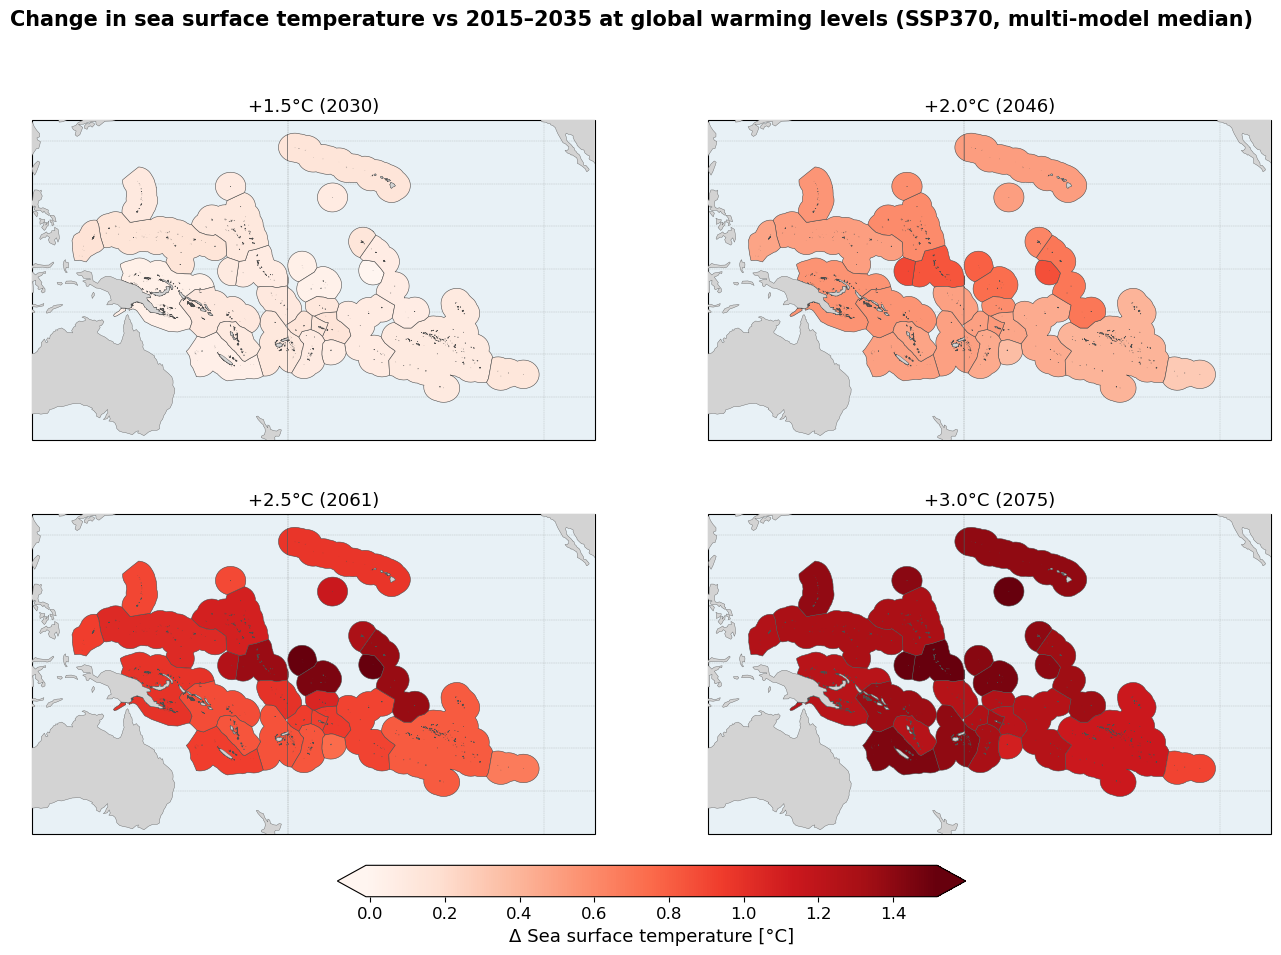

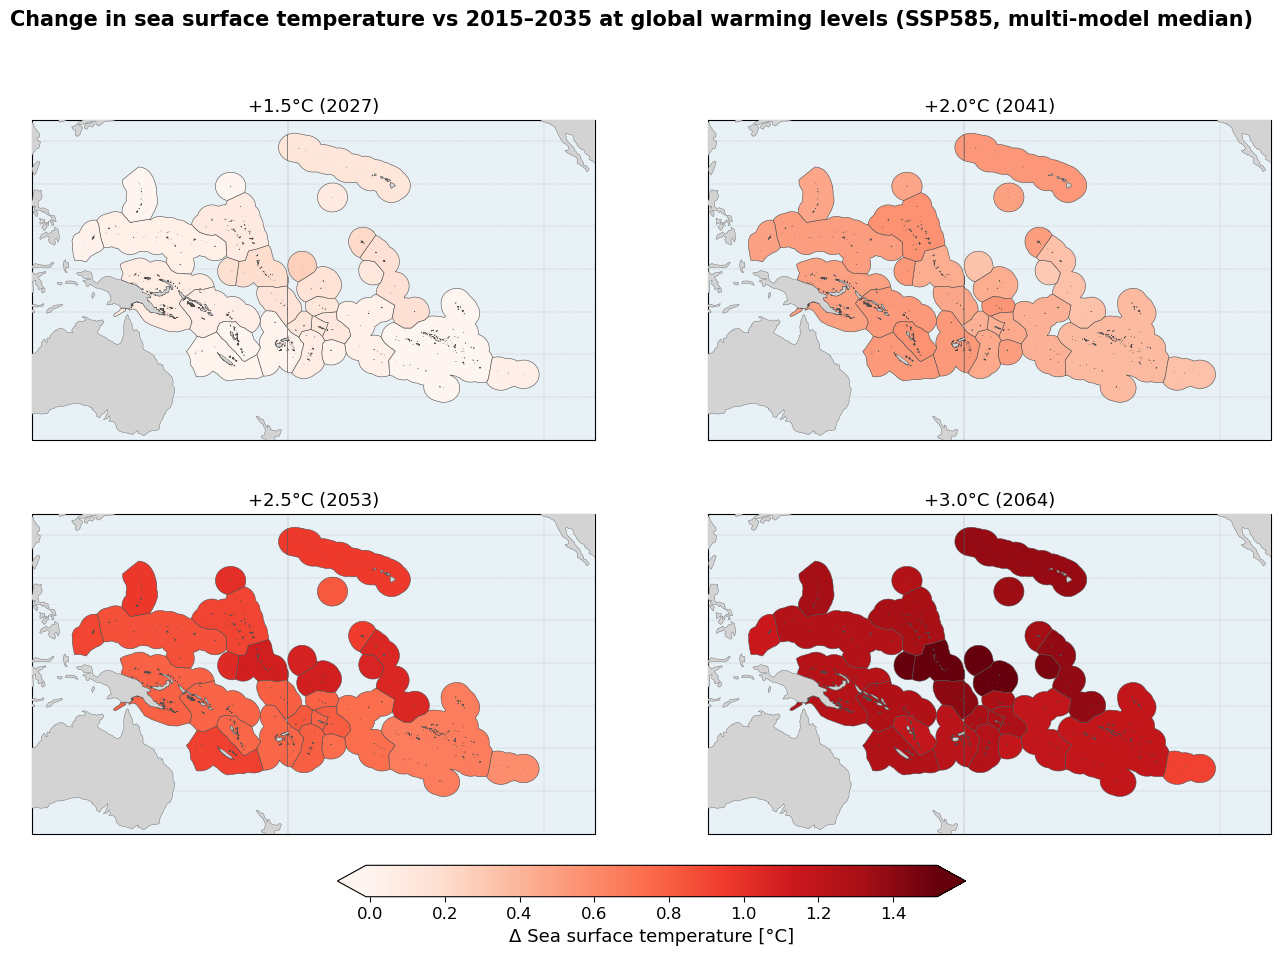

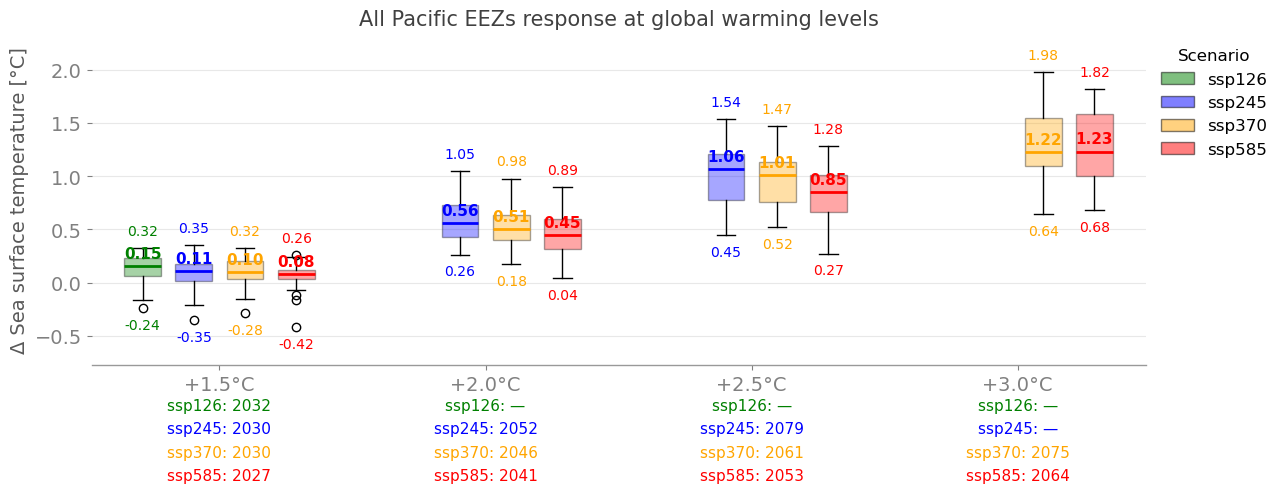

In [4]:
ds = reg.extract_regional_means("tos", eez, ssp_scenarios)
figs, tables = reg.indicator_report(ds, "tos", scenario_info, eez, ssp_scenarios, map_scenario, fig_dir, tables_dir)
glue("tos_fig", figs["levels"], display=False)
reg.show_tables(tables)


### Sea surface temperature series

Change in annual sea surface temperature relative to each model's 2015–2035 mean, averaged over all the Pacific EEZs: multi-model median for each scenario, with the 10th–90th percentile range across models shaded (using the change removes each model's mean bias). The table gives the decadal means of the multi-model median change.


**Change in sea surface temperature vs 2015–2035 (°C): decadal mean of the multi-model median**

SSP126  SSP245  SSP370  SSP585
region           Decade                                
All Pacific EEZs 2015    -0.092  -0.121  -0.128  -0.128
                 2025     0.096   0.107   0.121   0.113
                 2035     0.240   0.299   0.353   0.405
                 2045     0.342   0.524   0.621   0.709
                 2055     0.386   0.712   0.929   1.075
                 2065     0.431   0.865   1.195   1.530
                 2075     0.425   0.995   1.494   1.900
                 2085     0.396   1.122   1.816   2.352
                 2095     0.358   1.184   2.129   2.762

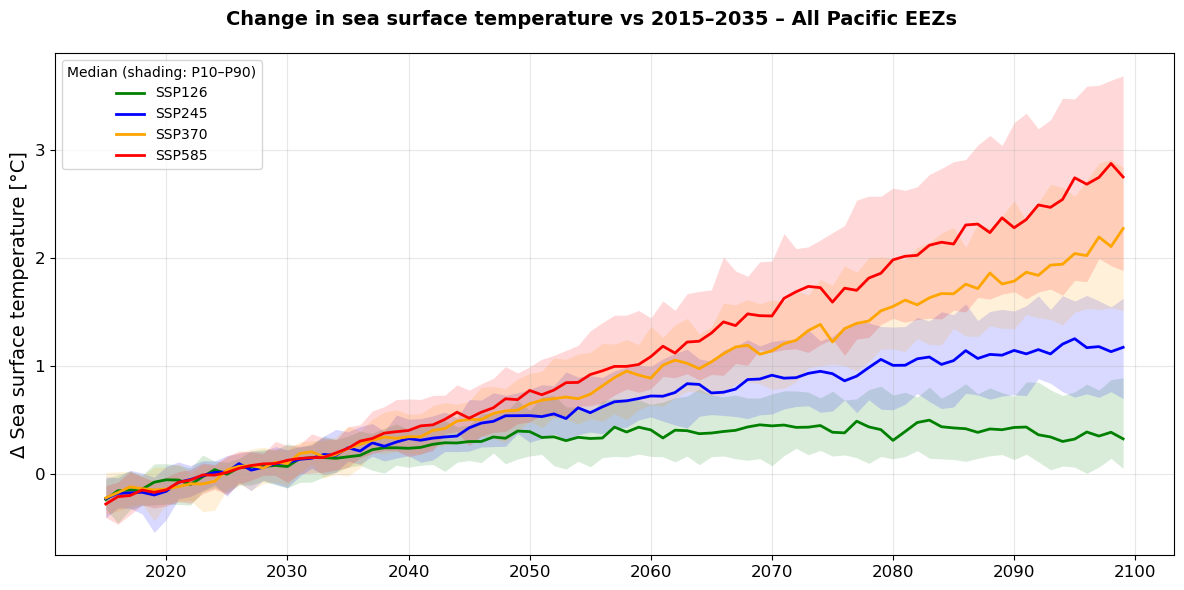

In [5]:
fig, table = reg.series_report(ds, "tos", "Sea surface temperature", "°C", ssp_scenarios, fig_dir, tables_dir)
reg.show_tables({"series": table})
